# Proyecto: Procesamiento, Modulación y Reconstrucción de Señal de Voz
**Curso:** Comunicaciones 1  
---
### Objetivos del Proyecto:
1. **Grabación de la señal:** Nota de voz en formato WAV (frase corta, 2 a 5 s).
2. **Reproducción y análisis original:** Carga, análisis temporal y espectral (FFT), identificación de $f_s$.
3. **Muestreo y digitalización:** Valores discretos $x[n]$, gráfica stem, cuantización uniforme PCM de 8 bits y flujo binario.
4. **Modulación:** Modulación de Amplitud (AM convencional) con portadora $f_c$ y gráfica temporal/espectral.
5. **Demodulación:** Demodulación coherente con filtro pasa-bajos para recuperar la señal mensaje.
6. **Reconstrucción:** Generación de nuevo archivo WAV y comparación gráfica y auditiva (MSE, SNR, correlación $r$).

In [1]:
import os
import numpy as np
import scipy.io.wavfile as wav
import scipy.signal as signal
import matplotlib.pyplot as plt
from IPython.display import Audio, display

plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10
print('Librerías importadas correctamente.')

Librerías importadas correctamente.


---
## 1 y 2. Reproducción y Análisis de la Señal Original
Cargamos la nota de voz almacenada en `audio/just_do_it.wav` y calculamos sus parámetros físicos y estadísticos.

In [2]:
ruta_wav = 'audio/just_do_it.wav'
fs, audio_orig = wav.read(ruta_wav)

if audio_orig.ndim > 1:
    audio_orig = audio_orig[:, 0]
if np.issubdtype(audio_orig.dtype, np.integer):
    audio_orig = audio_orig.astype(np.float32) / np.iinfo(audio_orig.dtype).max
else:
    audio_orig = audio_orig.astype(np.float32)
audio_orig = audio_orig / np.max(np.abs(audio_orig))

N = len(audio_orig)
duracion = N / fs
tiempo = np.arange(N) / fs

print(f'Frecuencia de muestreo (fs): {fs} Hz ({fs/1000:.1f} kHz)')
print(f'Número de muestras (N): {N:,}')
print(f'Duración: {duracion:.2f} segundos')

# Reproductor de audio original
display(Audio(audio_orig, rate=fs))

Frecuencia de muestreo (fs): 48000 Hz (48.0 kHz)
Número de muestras (N): 114,240
Duración: 2.38 segundos


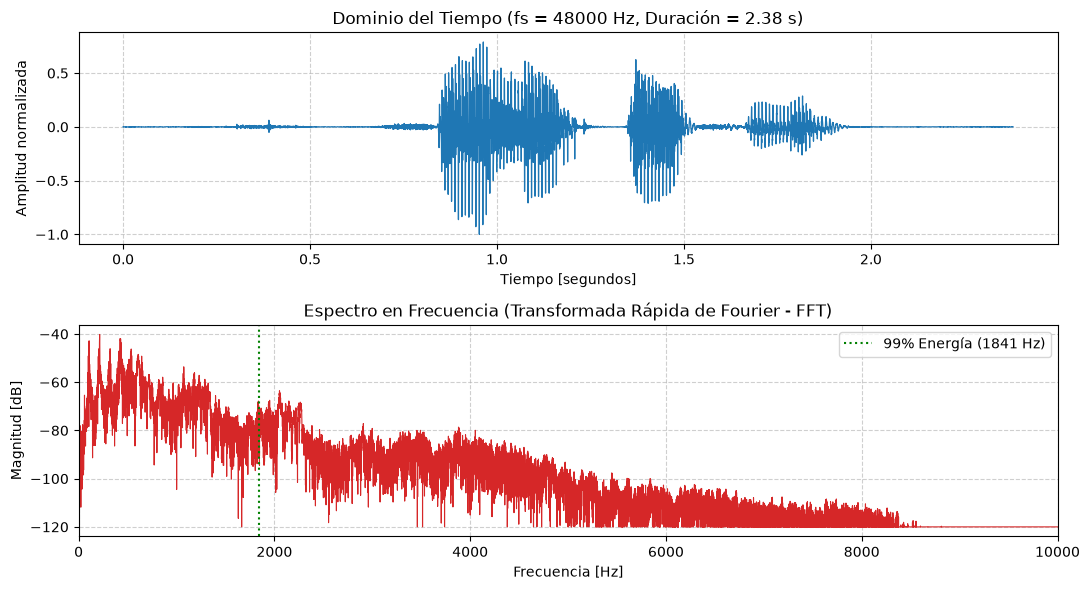

In [3]:
# Análisis Espectral mediante FFT
fft_vals = np.fft.rfft(audio_orig)
freqs = np.fft.rfftfreq(N, 1/fs)
fft_mag = np.abs(fft_vals) / N
fft_db = 20 * np.log10(np.maximum(fft_mag, 1e-6))

# Ancho de banda al 99% de energía
pot_acum = np.cumsum(fft_mag**2)
idx_99 = np.where(pot_acum >= 0.99 * pot_acum[-1])[0][0]
bw_99 = freqs[idx_99]

fig, axs = plt.subplots(2, 1, figsize=(11, 6))
axs[0].plot(tiempo, audio_orig, color='#1f77b4', lw=0.9)
axs[0].set_title(f'Dominio del Tiempo (fs = {fs} Hz, Duración = {duracion:.2f} s)')
axs[0].set_xlabel('Tiempo [segundos]')
axs[0].set_ylabel('Amplitud normalizada')
axs[0].grid(True, linestyle='--', alpha=0.6)

axs[1].plot(freqs, fft_db, color='#d62728', lw=0.8)
axs[1].axvline(bw_99, color='green', linestyle=':', label=f'99% Energía ({bw_99:.0f} Hz)')
axs[1].set_title('Espectro en Frecuencia (Transformada Rápida de Fourier - FFT)')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Magnitud [dB]')
axs[1].set_xlim(0, 10000)
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
## 3. Muestreo y Digitalización (PCM)
El muestreo discretiza el eje del tiempo ($x[n] = x(n T_s)$), mientras que la cuantización discretiza el eje de amplitud.
- Cuantización uniforme de 8 bits ($L = 256$ niveles).
- Paso de cuantización: $\Delta = \frac{x_{max} - x_{min}}{L - 1}$.
- Error de cuantización: $e[n] = x[n] - x_q[n]$, acotado por $\pm \Delta / 2$.

In [4]:
n_bits = 8
num_niveles = 2 ** n_bits
q_min, q_max = -1.0, 1.0
delta_q = (q_max - q_min) / (num_niveles - 1)

indices_cuant = np.clip(np.round((audio_orig - q_min) / delta_q), 0, num_niveles - 1).astype(int)
audio_pcm = indices_cuant * delta_q + q_min
error_cuant = audio_orig - audio_pcm
sqnr = 10 * np.log10(np.mean(audio_orig**2) / np.mean(error_cuant**2))

print(f'Resolución: {n_bits} bits ({num_niveles} niveles de cuantización)')
print(f'Paso de cuantización (Delta): {delta_q:.6f}')
print(f'SQNR (Relación Señal a Ruido de Cuantización): {sqnr:.2f} dB')
bits_ejemplo = [f'{idx:08b}' for idx in indices_cuant[1000:1005]]
print(f'Muestra de tren binario PCM (muestras 1000 a 1004): {" ".join(bits_ejemplo)}')

# Guardar audio PCM digitalizado
wav.write('audio/senal_digitalizada_pcm_8bits.wav', fs, audio_pcm.astype(np.float32))
display(Audio(audio_pcm, rate=fs))

Resolución: 8 bits (256 niveles de cuantización)
Paso de cuantización (Delta): 0.007843
SQNR (Relación Señal a Ruido de Cuantización): 31.73 dB
Muestra de tren binario PCM (muestras 1000 a 1004): 01111111 01111111 01111111 01111111 01111111


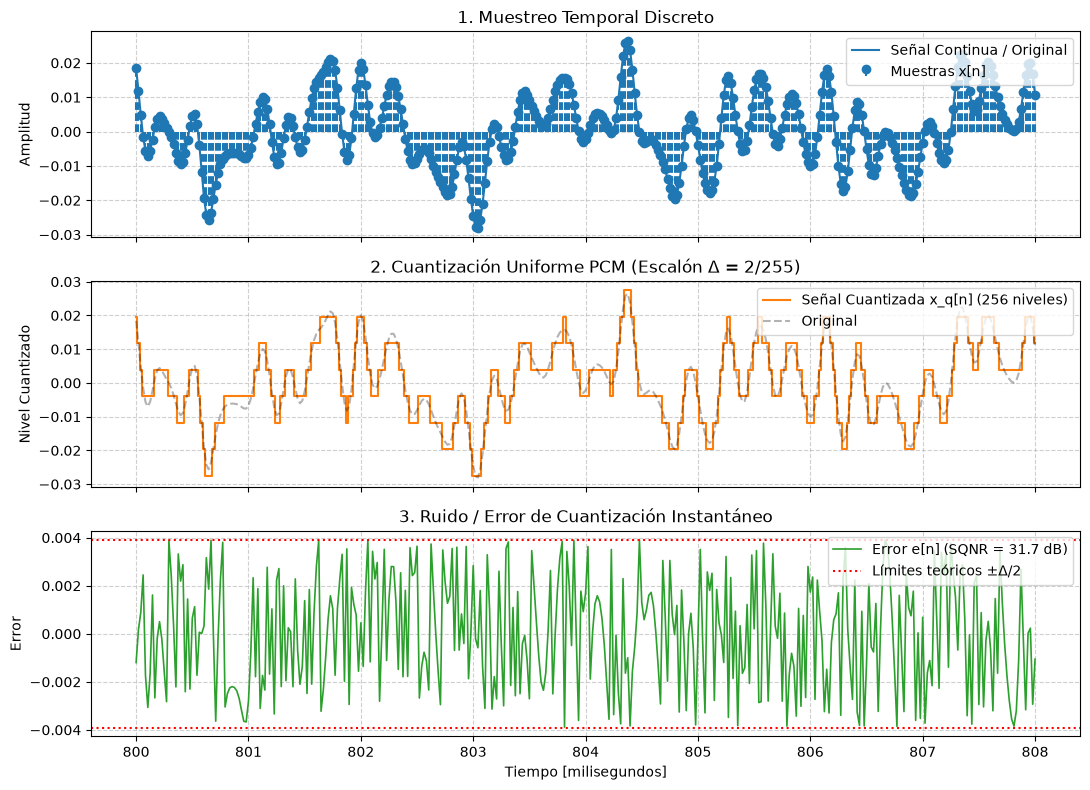

In [5]:
# Gráfica de Muestreo Discreto y Cuantización (Zoom 8 ms)
mask_zoom = (tiempo >= 0.800) & (tiempo <= 0.808)
t_ms = tiempo[mask_zoom] * 1000

fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axs[0].plot(t_ms, audio_orig[mask_zoom], label='Señal Continua / Original', color='#1f77b4', lw=1.5)
axs[0].stem(t_ms, audio_orig[mask_zoom], linefmt='C0--', markerfmt='C0o', basefmt=' ', label='Muestras x[n]')
axs[0].set_title('1. Muestreo Temporal Discreto')
axs[0].set_ylabel('Amplitud')
axs[0].legend(loc='upper right')
axs[0].grid(True, linestyle='--', alpha=0.6)

axs[1].step(t_ms, audio_pcm[mask_zoom], where='mid', label='Señal Cuantizada x_q[n] (256 niveles)', color='#ff7f0e', lw=1.5)
axs[1].plot(t_ms, audio_orig[mask_zoom], 'k--', alpha=0.3, label='Original')
axs[1].set_title('2. Cuantización Uniforme PCM (Escalón Δ = 2/255)')
axs[1].set_ylabel('Nivel Cuantizado')
axs[1].legend(loc='upper right')
axs[1].grid(True, linestyle='--', alpha=0.6)

axs[2].plot(t_ms, error_cuant[mask_zoom], color='#2ca02c', lw=1.2, label=f'Error e[n] (SQNR = {sqnr:.1f} dB)')
axs[2].axhline(delta_q/2, color='red', linestyle=':', label=r'Límites teóricos $\pm \Delta/2$')
axs[2].axhline(-delta_q/2, color='red', linestyle=':')
axs[2].set_title('3. Ruido / Error de Cuantización Instantáneo')
axs[2].set_xlabel('Tiempo [milisegundos]')
axs[2].set_ylabel('Error')
axs[2].legend(loc='upper right')
axs[2].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

---
## 4. Modulación en Amplitud (AM)
Implementamos modulación de la señal de voz con portadora sinusoidal:
$$s_{AM}(t) = A_c [1 + k_a \cdot m_n(t)] \cos(2\pi f_c t)$$
- $f_c = 8000\text{ Hz}$ (portadora en rango audible).
- $k_a = 0.8$ (índice del $80\%$, sin sobremodulación).

In [6]:
# Filtro pasa-bajos para acondicionar el mensaje a 3.5 kHz
b_voz, a_voz = signal.butter(5, 3500 / (fs / 2), btype='low')
m_t = signal.filtfilt(b_voz, a_voz, audio_orig)
m_t = m_t / np.max(np.abs(m_t))

# Modulación AM Convencional
fc = 8000.0
Ac = 1.0
ka = 0.8

envolvente = Ac * (1.0 + ka * m_t)
portadora = np.cos(2 * np.pi * fc * tiempo)
s_am = envolvente * portadora

# Normalización para reproducción y guardado
s_am_norm = s_am / np.max(np.abs(s_am))
wav.write('audio/senal_modulada_AM.wav', fs, s_am_norm.astype(np.float32))
print(f'Señal modulada AM generada con éxito (fc = {fc:.0f} Hz):')
display(Audio(s_am_norm, rate=fs))

Señal modulada AM generada con éxito (fc = 8000 Hz):


### ★ Secuencia de Modulación Organizada en 4 Pasos:
1. **Señal original (la voz / moduladora):** $m(t)$
2. **Señal portadora:** $c(t) = \cos(2\pi f_c t)$
3. **La portadora y por encima la señal original (moduladora)**
4. **Señal resultante de multiplicar moduladora y portadora:** $s(t) = m(t) \cdot c(t)$

---
## 4B. Modulación en Frecuencia (FM)
A diferencia de AM donde la información viaja en la amplitud, en FM la **amplitud se mantiene estrictamente constante** ($A_c$) y la **frecuencia instantánea** varía en función directa de la señal de voz:
$$f_i(t) = f_c + k_f \cdot m(t)$$
La señal modulada en frecuencia se define mediante la integral de fase:
$$s_{FM}(t) = A_c \cos\left(2\pi f_c t + 2\pi k_f \int_0^t m(\tau) d\tau\right)$$
- **Regla de Carson (Ancho de Banda):** $B_{FM} = 2(\Delta f + B) = 2(k_f + B)$.

In [7]:
# Parámetros FM
fc_fm = 6000.0   # Portadora 6 kHz
delta_f = 2500.0 # Desviación de frecuencia 2.5 kHz
kf = delta_f

# Modulación FM
integral_m = np.cumsum(m_t) / fs
fase_fm = 2 * np.pi * fc_fm * tiempo + 2 * np.pi * kf * integral_m
s_fm = np.cos(fase_fm)
wav.write('audio/senal_modulada_FM.wav', fs, s_fm.astype(np.float32))

# Demodulación FM usando Discriminador de Frecuencia (Hilbert)
analitica = signal.hilbert(s_fm)
fase_desenv = np.unwrap(np.angle(analitica))
freq_inst = np.diff(fase_desenv) * fs / (2 * np.pi)
freq_inst = np.append(freq_inst, freq_inst[-1])
m_rec_fm = (freq_inst - fc_fm) / kf
b_fm, a_fm = signal.butter(5, 3200 / (fs / 2), btype='low')
m_rec_fm = signal.filtfilt(b_fm, a_fm, m_rec_fm)
m_rec_fm = m_rec_fm / np.max(np.abs(m_rec_fm))
wav.write('audio/senal_demodulada_FM.wav', fs, m_rec_fm.astype(np.float32))

corr_fm = np.corrcoef(m_t, m_rec_fm)[0, 1]
print(f'FM Modulada y Demodulada con éxito! Correlación r: {corr_fm:.5f}')
print('Audio Modulado FM (se escucha el tono oscilando en frecuencia):')
display(Audio(s_fm, rate=fs))
print('Audio Demodulado FM (voz recuperada):')
display(Audio(m_rec_fm, rate=fs))

FM Modulada y Demodulada con éxito! Correlación r: 0.99627
Audio Modulado FM (se escucha el tono oscilando en frecuencia):


Audio Demodulado FM (voz recuperada):


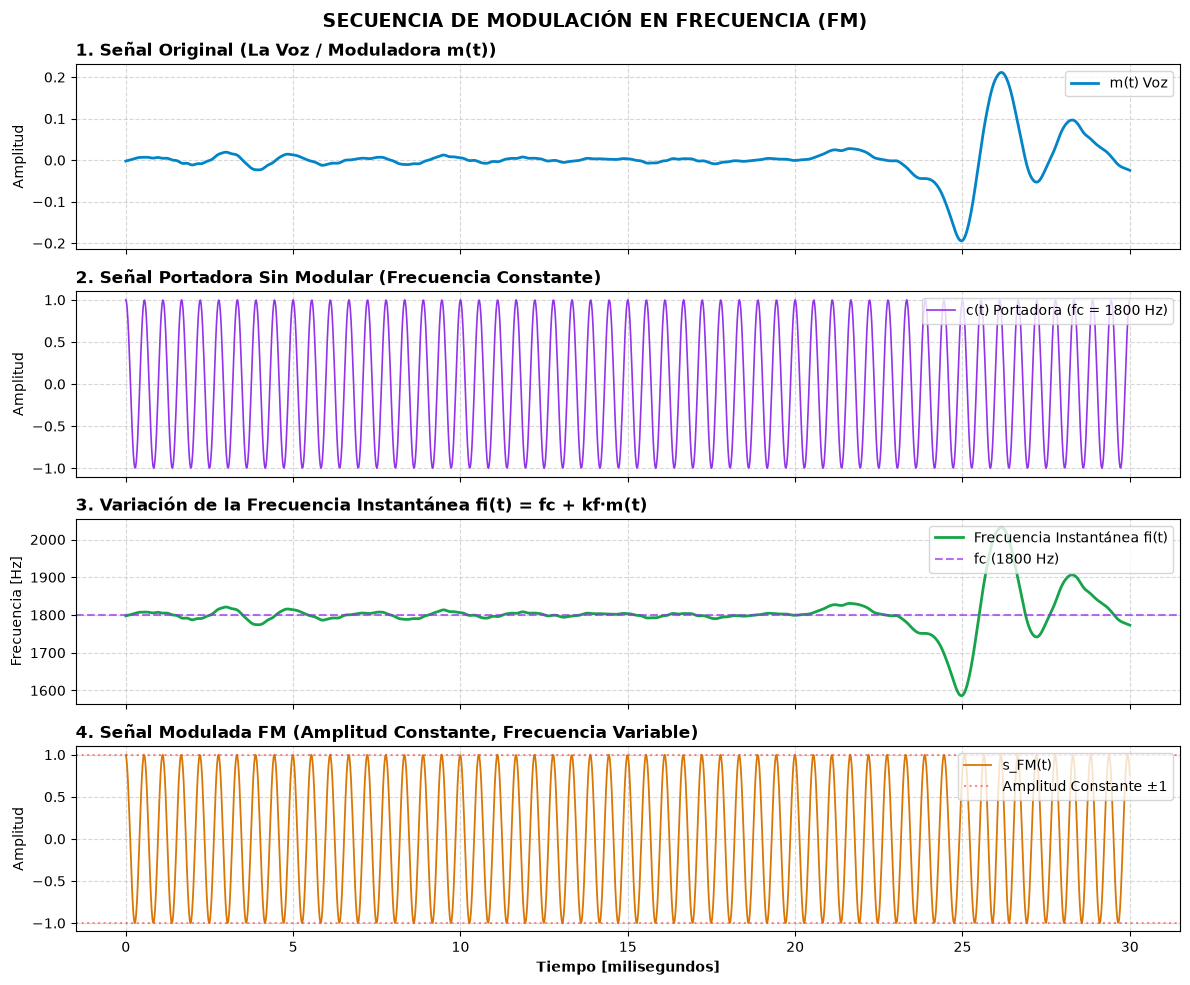

In [8]:
mask_4p = (tiempo >= 0.820) & (tiempo <= 0.850)
t_ms_4p = (tiempo[mask_4p] - 0.820) * 1000
# Gráfica de Modulación FM en 4 Pasos
fc_vis = 1800.0
kf_vis = 1100.0
c_fm_p = np.cos(2 * np.pi * fc_vis * tiempo)
fi_p = fc_vis + kf_vis * m_t
sfm_p = np.cos(2 * np.pi * fc_vis * tiempo + 2 * np.pi * kf_vis * integral_m)

fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
fig.suptitle('SECUENCIA DE MODULACIÓN EN FRECUENCIA (FM)', fontsize=14, fontweight='bold', y=0.98)

axs[0].plot(t_ms_4p, m_t[mask_4p], color='#0284c7', lw=2.0, label='m(t) Voz')
axs[0].set_title('1. Señal Original (La Voz / Moduladora m(t))', fontweight='bold', loc='left')
axs[0].set_ylabel('Amplitud')
axs[0].grid(True, linestyle='--', alpha=0.5)
axs[0].legend(loc='upper right')

axs[1].plot(t_ms_4p, c_fm_p[mask_4p], color='#9333ea', lw=1.2, label=f'c(t) Portadora (fc = {fc_vis:.0f} Hz)')
axs[1].set_title('2. Señal Portadora Sin Modular (Frecuencia Constante)', fontweight='bold', loc='left')
axs[1].set_ylabel('Amplitud')
axs[1].grid(True, linestyle='--', alpha=0.5)
axs[1].legend(loc='upper right')

axs[2].plot(t_ms_4p, fi_p[mask_4p], color='#16a34a', lw=2.0, label='Frecuencia Instantánea fi(t)')
axs[2].axhline(fc_vis, color='#9333ea', linestyle='--', alpha=0.7, label=f'fc ({fc_vis:.0f} Hz)')
axs[2].set_title('3. Variación de la Frecuencia Instantánea fi(t) = fc + kf·m(t)', fontweight='bold', loc='left')
axs[2].set_ylabel('Frecuencia [Hz]')
axs[2].grid(True, linestyle='--', alpha=0.5)
axs[2].legend(loc='upper right')

axs[3].plot(t_ms_4p, sfm_p[mask_4p], color='#d97706', lw=1.3, label='s_FM(t)')
axs[3].axhline(1.0, color='#ef4444', linestyle=':', alpha=0.6, label='Amplitud Constante ±1')
axs[3].axhline(-1.0, color='#ef4444', linestyle=':', alpha=0.6)
axs[3].set_title('4. Señal Modulada FM (Amplitud Constante, Frecuencia Variable)', fontweight='bold', loc='left')
axs[3].set_xlabel('Tiempo [milisegundos]', fontweight='bold')
axs[3].set_ylabel('Amplitud')
axs[3].grid(True, linestyle='--', alpha=0.5)
axs[3].legend(loc='upper right')

plt.tight_layout()
plt.show()

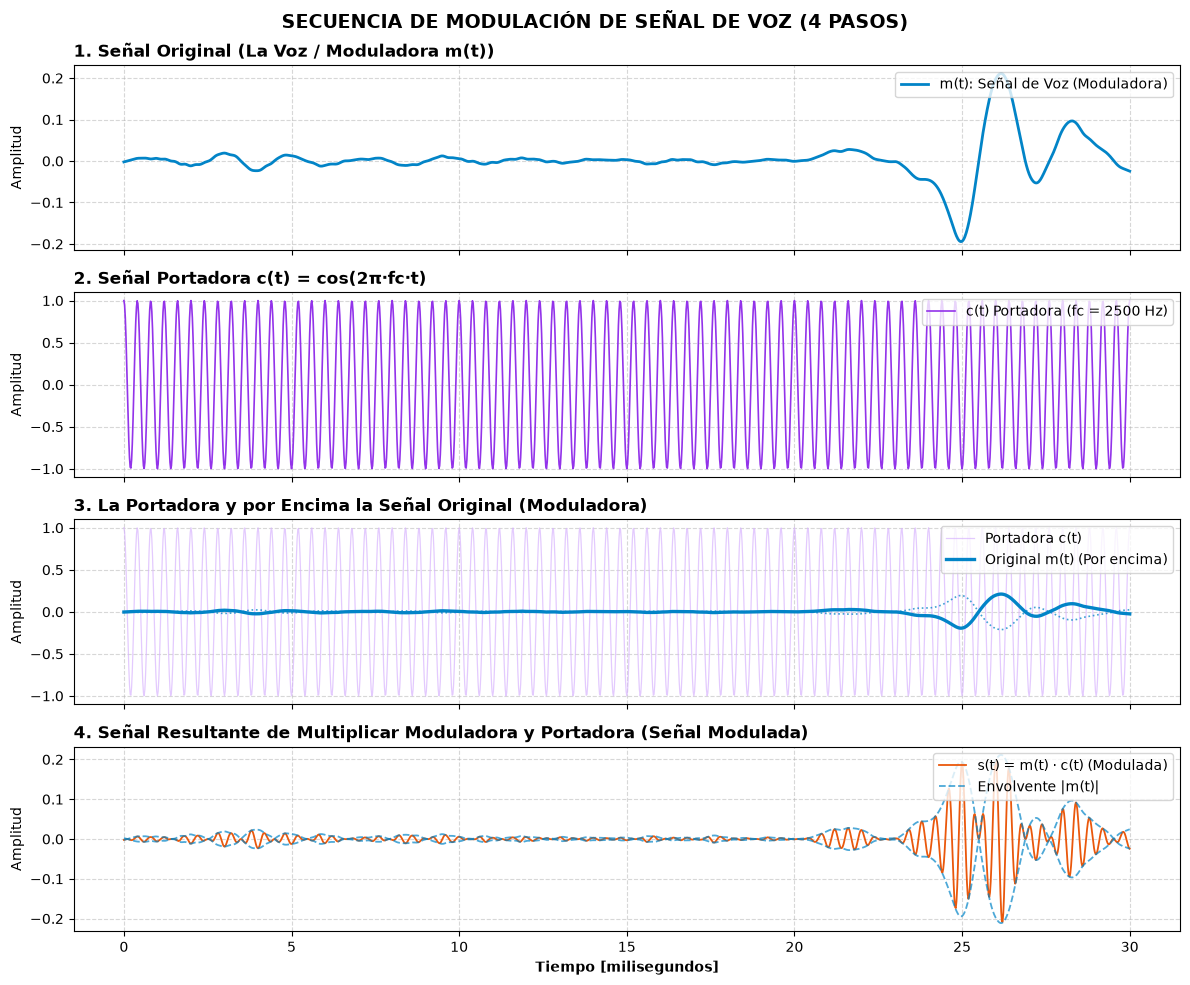

In [9]:
# 4 Pasos Organizados en una Ventana Nítida (30 ms)
t_i, t_f = 0.820, 0.850
mask_4p = (tiempo >= t_i) & (tiempo <= t_f)
t_ms_4p = (tiempo[mask_4p] - t_i) * 1000
fc_demo = 2500.0
c_demo = np.cos(2 * np.pi * fc_demo * tiempo)
s_prod = m_t * c_demo

fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
fig.suptitle('SECUENCIA DE MODULACIÓN DE SEÑAL DE VOZ (4 PASOS)', fontsize=14, fontweight='bold', y=0.98)

# 1. Señal original (la voz)
axs[0].plot(t_ms_4p, m_t[mask_4p], color='#0284c7', lw=2.0, label='m(t): Señal de Voz (Moduladora)')
axs[0].set_title('1. Señal Original (La Voz / Moduladora m(t))', fontweight='bold', loc='left')
axs[0].set_ylabel('Amplitud')
axs[0].grid(True, linestyle='--', alpha=0.5)
axs[0].legend(loc='upper right')

# 2. Señal portadora
axs[1].plot(t_ms_4p, c_demo[mask_4p], color='#9333ea', lw=1.2, label=f'c(t) Portadora (fc = {fc_demo:.0f} Hz)')
axs[1].set_title('2. Señal Portadora c(t) = cos(2π·fc·t)', fontweight='bold', loc='left')
axs[1].set_ylabel('Amplitud')
axs[1].grid(True, linestyle='--', alpha=0.5)
axs[1].legend(loc='upper right')

# 3. La portadora y por encima la señal original
axs[2].plot(t_ms_4p, c_demo[mask_4p], color='#d8b4fe', lw=0.9, alpha=0.7, label='Portadora c(t)')
axs[2].plot(t_ms_4p, m_t[mask_4p], color='#0284c7', lw=2.4, label='Original m(t) (Por encima)')
axs[2].plot(t_ms_4p, -m_t[mask_4p], color='#0284c7', lw=1.2, linestyle=':', alpha=0.75)
axs[2].set_title('3. La Portadora y por Encima la Señal Original (Moduladora)', fontweight='bold', loc='left')
axs[2].set_ylabel('Amplitud')
axs[2].grid(True, linestyle='--', alpha=0.5)
axs[2].legend(loc='upper right')

# 4. Multiplicación (Señal modulada)
axs[3].plot(t_ms_4p, s_prod[mask_4p], color='#ea580c', lw=1.3, label='s(t) = m(t) · c(t) (Modulada)')
axs[3].plot(t_ms_4p, np.abs(m_t[mask_4p]), color='#0284c7', lw=1.3, linestyle='--', alpha=0.7, label='Envolvente |m(t)|')
axs[3].plot(t_ms_4p, -np.abs(m_t[mask_4p]), color='#0284c7', lw=1.3, linestyle='--', alpha=0.7)
axs[3].set_title('4. Señal Resultante de Multiplicar Moduladora y Portadora (Señal Modulada)', fontweight='bold', loc='left')
axs[3].set_xlabel('Tiempo [milisegundos]', fontweight='bold')
axs[3].set_ylabel('Amplitud')
axs[3].grid(True, linestyle='--', alpha=0.5)
axs[3].legend(loc='upper right')

plt.tight_layout()
plt.show()

---
## 5. Demodulación Coherente
Multiplicamos por el oscilador local sincronizado $2\cos(2\pi f_c t)$:
$$v(t) = s_{AM}(t) \cdot 2\cos(2\pi f_c t) = A_c [1 + k_a m_n(t)] + A_c [1 + k_a m_n(t)] \cos(4\pi f_c t)$$
Un filtro pasa-bajos rechaza la componente en $2f_c$. Tras bloquear el nivel continuo (DC), se recupera el mensaje acústico.

In [10]:
# Mezclado coherente
v_t = s_am * (2.0 * np.cos(2 * np.pi * fc * tiempo))

# Filtrado paso-bajos
b_demod, a_demod = signal.butter(6, 3800 / (fs / 2), btype='low')
v_filtrada = signal.filtfilt(b_demod, a_demod, v_t)

# Eliminación de nivel DC y normalización
m_recuperada = v_filtrada - np.mean(v_filtrada)
m_recuperada = m_recuperada / np.max(np.abs(m_recuperada))

# Guardar y reproducir audio demodulado
wav.write('audio/senal_demodulada_AM.wav', fs, m_recuperada.astype(np.float32))
print('Señal demodulada reproducida:')
display(Audio(m_recuperada, rate=fs))

Señal demodulada reproducida:


---
## 6. Reconstrucción y Comparación Exhaustiva
Generamos el archivo WAV reconstruido definitivo y cuantificamos la calidad del sistema mediante:
1. **Correlación de Pearson ($r$):** Similitud temporal de las formas de onda.
2. **MSE (Mean Squared Error):** Desviación media cuadrática entre la señal original y la recuperada.
3. **SNR (Signal-to-Noise Ratio):** Relación de potencia útil frente al residuo de reconstrucción.

MÉTRICAS DE CALIDAD DE LA RECONSTRUCCIÓN:
• Coeficiente de correlación (r): 0.99867
• Error cuadrático medio (MSE):   5.071863e-04
• Relación señal a ruido (SNR):    13.48 dB


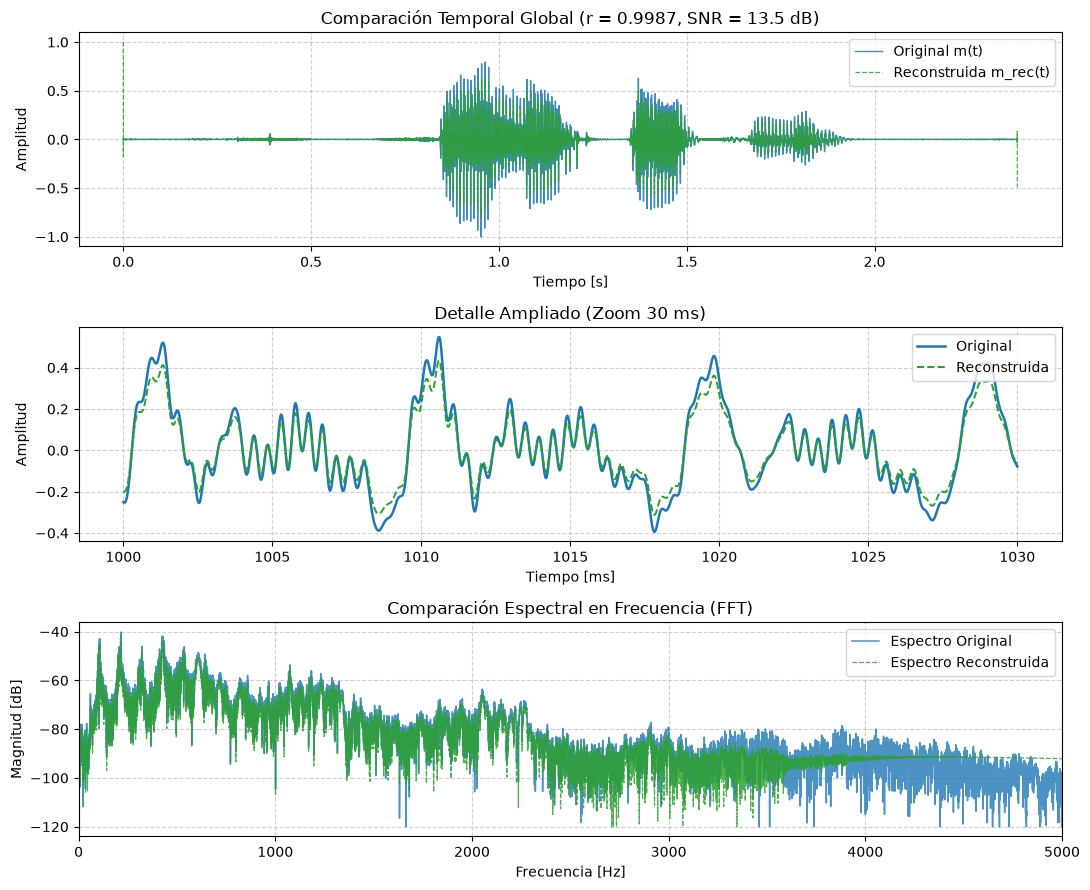

Audio Final Reconstruido:


In [11]:
audio_reconstruido = m_recuperada.copy()
wav.write('audio/senal_reconstruida.wav', fs, audio_reconstruido.astype(np.float32))

mse = np.mean((m_t - audio_reconstruido)**2)
snr = 10 * np.log10(np.mean(m_t**2) / max(mse, 1e-12))
corr = np.corrcoef(m_t, audio_reconstruido)[0, 1]

print('==============================================')
print('MÉTRICAS DE CALIDAD DE LA RECONSTRUCCIÓN:')
print('==============================================')
print(f'• Coeficiente de correlación (r): {corr:.5f}')
print(f'• Error cuadrático medio (MSE):   {mse:.6e}')
print(f'• Relación señal a ruido (SNR):    {snr:.2f} dB')
print('==============================================')

fig, axs = plt.subplots(3, 1, figsize=(11, 9))
axs[0].plot(tiempo, m_t, label='Original m(t)', color='#1f77b4', lw=1.0, alpha=0.85)
axs[0].plot(tiempo, audio_reconstruido, label='Reconstruida m_rec(t)', color='#2ca02c', lw=0.9, linestyle='--', alpha=0.85)
axs[0].set_title(f'Comparación Temporal Global (r = {corr:.4f}, SNR = {snr:.1f} dB)')
axs[0].set_xlabel('Tiempo [s]')
axs[0].set_ylabel('Amplitud')
axs[0].legend(loc='upper right')
axs[0].grid(True, linestyle='--', alpha=0.6)

mask_zoom_comp = (tiempo >= 1.00) & (tiempo <= 1.03)
axs[1].plot(tiempo[mask_zoom_comp]*1000, m_t[mask_zoom_comp], label='Original', color='#1f77b4', lw=1.8)
axs[1].plot(tiempo[mask_zoom_comp]*1000, audio_reconstruido[mask_zoom_comp], label='Reconstruida', color='#2ca02c', lw=1.4, linestyle='--')
axs[1].set_title('Detalle Ampliado (Zoom 30 ms)')
axs[1].set_xlabel('Tiempo [ms]')
axs[1].set_ylabel('Amplitud')
axs[1].legend(loc='upper right')
axs[1].grid(True, linestyle='--', alpha=0.6)

fft_rec = np.abs(np.fft.rfft(audio_reconstruido)) / N
fft_rec_db = 20 * np.log10(np.maximum(fft_rec, 1e-6))
axs[2].plot(freqs, fft_db, label='Espectro Original', color='#1f77b4', lw=1.1, alpha=0.8)
axs[2].plot(freqs, fft_rec_db, label='Espectro Reconstruida', color='#2ca02c', lw=0.9, linestyle='--', alpha=0.85)
axs[2].set_title('Comparación Espectral en Frecuencia (FFT)')
axs[2].set_xlabel('Frecuencia [Hz]')
axs[2].set_ylabel('Magnitud [dB]')
axs[2].set_xlim(0, 5000)
axs[2].legend(loc='upper right')
axs[2].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print('Audio Final Reconstruido:')
display(Audio(audio_reconstruido, rate=fs))